In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dart_austinsbridge.csv to dart_austinsbridge.csv
Saving exe_thorverton.csv to exe_thorverton.csv
Saving rainfall_exeter.csv to rainfall_exeter.csv
Saving tamar_gunnislake.csv to tamar_gunnislake.csv


In [ ]:
import pandas as pd

files = {
    "Exe": "exe_thorverton.csv",
    "Tamar": "tamar_gunnislake.csv",
    "Dart": "dart_austinsbridge.csv",
    "Rainfall": "rainfall_exeter.csv",
}

frames = []
for site, filename in files.items():
    df = pd.read_csv(filename, usecols=["date", "value", "completeness", "quality"])
    df["date"] = pd.to_datetime(df["date"])
    df["site"] = site
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
print(data.shape)
data.head()

(21881, 5)


,date,value,completeness,quality,site
0,2010-01-01,26.033,Complete,Good,Exe
1,2010-01-02,22.424,Complete,Good,Exe
2,2010-01-03,18.972,Complete,Good,Exe
3,2010-01-04,16.018,Complete,Good,Exe
4,2010-01-05,14.408,Complete,Good,Exe


In [ ]:
qa = data.groupby("site").agg(
    rows=("value", "size"),
    start=("date", "min"),
    end=("date", "max"),
    good_pct=("quality", lambda q: round((q == "Good").mean() * 100, 1)),
    estimated=("quality", lambda q: (q == "Estimated").sum()),
    suspect=("quality", lambda q: (q == "Suspect").sum()),
    unchecked=("quality", lambda q: (q == "Unchecked").sum()),
)
qa

,rows,start,end,good_pct,estimated,suspect,unchecked
site,,,,,,,
Dart,6138,2010-01-01,2026-10-21,95.9,153,0,97
Exe,6138,2010-01-01,2026-10-21,88.8,585,0,101
Rainfall,3467,2017-04-25,2026-10-21,94.0,0,3,205
Tamar,6138,2010-01-01,2026-10-21,97.4,7,108,42


In [ ]:
suspect = data[data["quality"] == "Suspect"]
suspect.groupby("site")["date"].agg(["min", "max", "count"])

,min,max,count
site,,,
Rainfall,2024-11-20,2024-11-22,3
Tamar,2025-03-11,2025-06-26,108


In [ ]:
clean = data.copy()
clean.loc[clean["quality"] == "Suspect", "value"] = None

wide = clean.pivot(index="date", columns="site", values="value")
print(wide.isna().sum())
wide.tail()

site
Dart           0
Exe            0
Rainfall    2674
Tamar        108
dtype: int64


site,Dart,Exe,Rainfall,Tamar
date,,,,
2026-10-17,2.167,3.477,0.00,4.933
2026-10-18,1.976,3.326,0.79,4.076
2026-10-19,1.927,3.210,1.44,3.827
2026-10-20,1.956,3.105,2.73,3.837
2026-10-21,2.050,3.423,0.09,4.155


In [ ]:
from google.colab import files as colab_files

colab_files.download("river_flows_clean.csv")
colab_files.download("qa_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

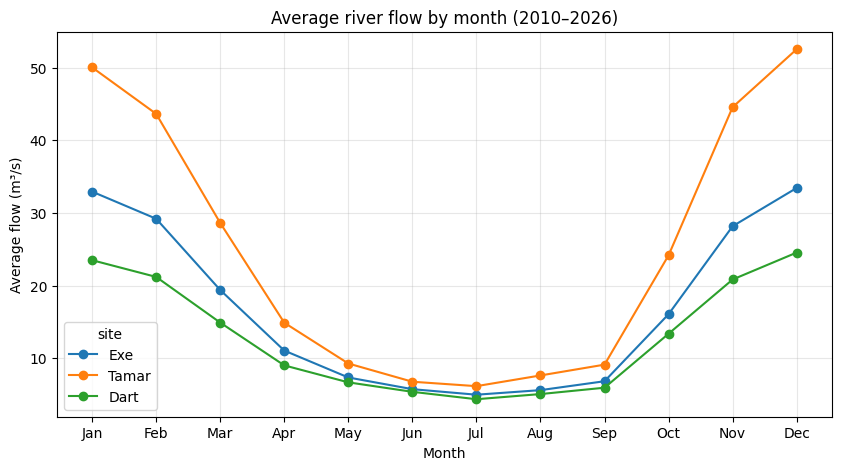

In [ ]:
import matplotlib.pyplot as plt

rivers = ["Exe", "Tamar", "Dart"]
monthly = wide[rivers].groupby(wide.index.month).mean()

monthly.plot(marker="o", figsize=(10, 5))
plt.title("Average river flow by month (2010–2026)")
plt.xlabel("Month")
plt.ylabel("Average flow (m³/s)")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.grid(alpha=0.3)
plt.show()

Low-flow threshold (Q95):
site
Exe      2.00
Tamar    2.86
Dart     1.76
Name: 0.05, dtype: float64


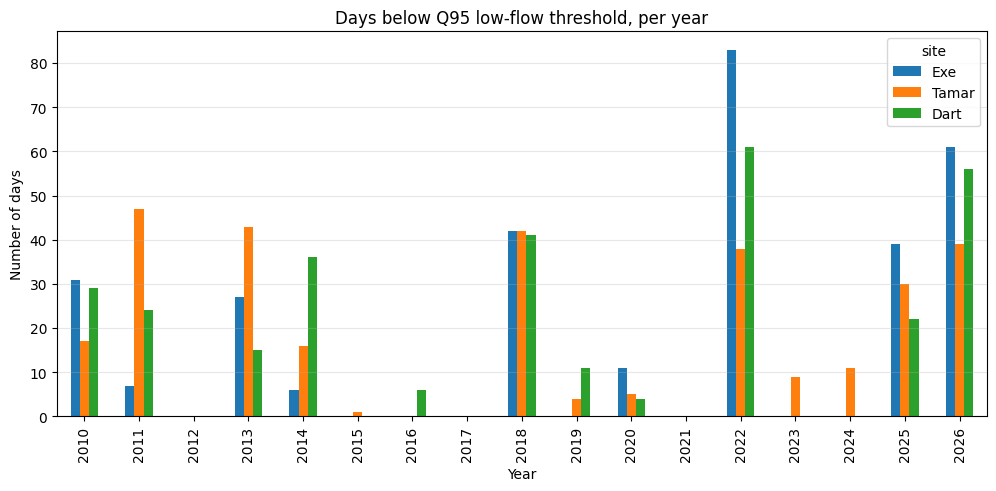

In [ ]:
q95 = wide[rivers].quantile(0.05)
print("Low-flow threshold (Q95):")
print(q95.round(2))

low_days = (wide[rivers] < q95).groupby(wide.index.year).sum()

low_days.plot(kind="bar", figsize=(12, 5))
plt.title("Days below Q95 low-flow threshold, per year")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
october = wide[rivers][wide.index.month == 10]

normal_oct = october[october.index.year < 2026].mean()
oct_2026 = october[october.index.year == 2026].mean()

comparison = pd.DataFrame({
    "Normal October (2010–2025)": normal_oct.round(1),
    "October 2026 so far": oct_2026.round(1),
    "% of normal": (oct_2026 / normal_oct * 100).round(0),
})
comparison

,Normal October (2010–2025),October 2026 so far,% of normal
site,,,
Exe,16.6,2.8,17.0
Tamar,25.0,3.8,15.0
Dart,13.8,2.1,15.0


In [ ]:
early_oct = wide[rivers][(wide.index.month == 10) & (wide.index.day <= 21)]
yearly = early_oct.groupby(early_oct.index.year).mean().round(1)
yearly.sort_values("Exe").head(5)

site,Exe,Tamar,Dart
date,,,
2022,2.7,4.9,6.5
2026,2.8,3.8,2.1
2016,5.1,6.0,3.6
2015,5.2,9.4,6.3
2025,5.5,9.8,8.5


In [ ]:
import numpy as np

monthly = wide["Exe"].resample("MS").mean().to_frame("flow")
monthly["month"] = monthly.index.month
monthly["last_month"] = monthly["flow"].shift(1)

model_data = monthly.dropna()
model_data = model_data[model_data.index < "2026-10-01"]
model_data.tail()

,flow,month,last_month
date,,,
2026-05-01,3.558452,5,5.609300
2026-06-01,5.423533,6,3.558452
2026-07-01,1.944161,7,5.423533
2026-08-01,1.676419,8,1.944161
2026-09-01,2.171733,9,1.676419


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X = pd.get_dummies(model_data["month"], prefix="m").astype(int)
X["log_last_month"] = np.log(model_data["last_month"])
y = np.log(model_data["flow"])

train = model_data.index < "2023-01-01"
test = ~train

model = LinearRegression()
model.fit(X[train], y[train])

predicted = np.exp(model.predict(X[test]))
actual = model_data.loc[test, "flow"]

seasonal_avg = model_data[train].groupby("month")["flow"].mean()
baseline = model_data.loc[test, "month"].map(seasonal_avg)

print("Model error (MAE):          ", round(mean_absolute_error(actual, predicted), 1))
print("Seasonal-average error (MAE):", round(mean_absolute_error(actual, baseline), 1))

Model error (MAE):           7.2
Seasonal-average error (MAE): 7.4


In [ ]:
model.fit(X, y)

oct_2026 = monthly.loc["2026-10-01", "flow"]

new = pd.DataFrame(0, index=[0], columns=X.columns)
new["m_11"] = 1
new["log_last_month"] = np.log(oct_2026)

log_pred = model.predict(new)[0]
spread = (y - model.predict(X)).std()

print(f"October 2026 average so far: {oct_2026:.1f} m³/s")
print(f"Forecast November 2026:      {np.exp(log_pred):.1f} m³/s")
print(f"Likely range:                {np.exp(log_pred - spread):.1f} to {np.exp(log_pred + spread):.1f} m³/s")
print(f"Normal November:             {seasonal_avg[11]:.1f} m³/s")

October 2026 average so far: 2.8 m³/s
Forecast November 2026:      14.2 m³/s
Likely range:                8.3 to 24.4 m³/s
Normal November:             26.6 m³/s


In [ ]:
oct_flow = monthly[monthly["month"] == 10]["flow"]
nov_flow = monthly[monthly["month"] == 11]["flow"]

history = pd.DataFrame({
    "October": oct_flow.values[:len(nov_flow)],
    "November": nov_flow.values,
}, index=nov_flow.index.year).round(1)

history.sort_values("October").head(6)

,October,November
date,,
2022,4.4,38.4
2016,4.5,25.0
2015,5.4,25.8
2018,6.2,15.5
2014,7.6,29.6
2025,10.1,32.6


In [ ]:
dash = clean[clean["site"] != "Rainfall"].copy()
dash = dash.rename(columns={"value": "flow"})
dash["year"] = dash["date"].dt.year
dash["month"] = dash["date"].dt.month
dash["q95_threshold"] = dash["site"].map(q95).round(2)
dash["low_flow_day"] = (dash["flow"] < dash["q95_threshold"]).astype(int)

dash = dash[["date", "site", "flow", "quality", "year", "month", "q95_threshold", "low_flow_day"]]
dash.to_csv("dashboard_flows.csv", index=False)

from google.colab import files as colab_files
colab_files.download("dashboard_flows.csv")
print(dash.shape)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(18414, 8)


## What I Found

**The data:** I used 17 years of daily river flow data (2010 to 2026) from three Devon and Cornwall rivers: the Exe, the Tamar and the Dart. I also added daily rainfall from Exeter, which only goes back to 2017. All of it came from the Environment Agency. That's about 22,000 rows in total.

### 1. Checking the data first
- No days were missing and nothing was duplicated.
- The Tamar had a problem: 108 days in a row (March to June 2025) were marked "Suspect". It looks like the gauge wasn't working properly. I left those days blank instead of guessing the numbers.
- The Exe had 585 days filled in by the Environment Agency's own estimates. I kept these.
- The most recent October 2026 readings haven't been checked yet, so they might change.

### 2. How rivers change through the year
- Rivers are fullest in December and January, and lowest in July. Summer flow is about ten times lower than winter.
- The biggest drop happens between March and May. If spring is dry, rivers start the summer already low.

### 3. Dry years
- I counted how many days each year the rivers fell below a standard "low flow" level.
- 2022 was the worst year, with about 80 low days on the Exe.
- 2026 is already the second worst year, and it isn't over yet.
- The Tamar's 2025 figure is probably too low, because of the 108 days of bad data.

### 4. Right now
- In early October 2026, the rivers are carrying less than a fifth of their normal water.
- For the Tamar and Dart, this is the lowest early October in 17 years.
- October 2025 was also very low, so this is the second dry autumn in a row.

### What this data can't tell us
- Rainfall data only starts in 2017.
- Three rivers give a good picture, but not the full region.
- The latest numbers could still be corrected.
### 5. Forecast for November 2026
- I built a simple model that predicts next month's flow from the month of the year and last month's flow. I trained it on 2010–2022 and tested it on 2023–2026.
- It only beat a simple "normal for that month" guess by about 3%, because the main driver, future rainfall, isn't something past flows can predict.
- The model forecasts about 14 m³/s for the Exe in November (likely range 8 to 24), compared with a normal of 27.
- But history disagrees: after the six driest Octobers on record, November always recovered to between 15 and 38 m³/s.
- My conclusion: recovery is likely, but not guaranteed. This October is drier than any in the record, so a dry November is the main risk to watch.